# Sieci neuronowe i deep learning - Lab 1

## Wprowadzenie do deep learningu i ewaluacji modeli

W tym laboratorium budujemy pierwszy prosty eksperyment uczenia nadzorowanego. Część związana z danymi, podziałem, skalowaniem, baseline'ami i metrykami korzysta ze `scikit-learn`, ponieważ te elementy są wspólne dla wielu frameworków deep learningu.

Wersja modelu: **PyTorch**. Notebook jest tłumaczeniem wersji TensorFlow/Keras na PyTorch.

## Ćwiczenie 1

- Załaduj zbiór danych `breast_cancer`.
- Sprawdź liczbę przykładów, liczbę cech, nazwy klas i liczności klas.
- Obejrzyj kilka wybranych cech. Zastanów się, czy dane wymagają skalowania.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

In [2]:
data = load_breast_cancer()

X = data.data.astype("float32")
y = data.target.astype("int64")

print("Liczba przykładów:", X.shape[0])
print("Liczba cech:", X.shape[1])
print("Nazwy klas:", dict(enumerate(data.target_names)))
print("Liczności klas:", dict(zip(*np.unique(y, return_counts=True))))

Liczba przykładów: 569
Liczba cech: 30
Nazwy klas: {0: np.str_('malignant'), 1: np.str_('benign')}
Liczności klas: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}


In [3]:
print("Kształt macierzy X:", X.shape)
print("Zakres wartości cech (min pierwszych 5):", X[:, :5].min(axis=0).round(3))
print("Zakres wartości cech (max pierwszych 5):", X[:, :5].max(axis=0).round(3))
print("Pierwsze 10 etykiet:", y[:10])
print("Nazwy 5 pierwszych cech:", list(data.feature_names[:5]))
print("Nazwy 5 ostatnich cech:", list(data.feature_names[-5:]))


Kształt macierzy X: (569, 30)
Zakres wartości cech (min pierwszych 5): [6.981e+00 9.710e+00 4.379e+01 1.435e+02 5.300e-02]
Zakres wartości cech (max pierwszych 5): [2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.630e-01]
Pierwsze 10 etykiet: [0 0 0 0 0 0 0 0 0 0]
Nazwy 5 pierwszych cech: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]
Nazwy 5 ostatnich cech: [np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]


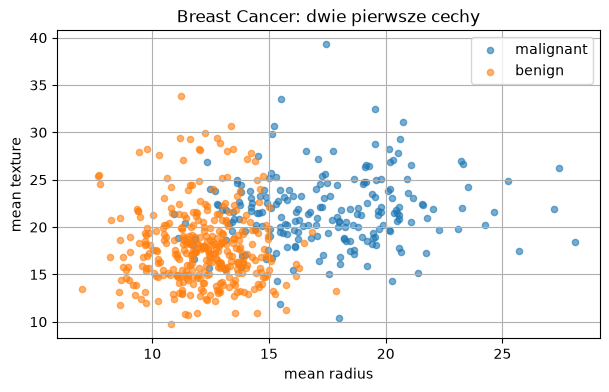

In [4]:
feature_x = 0
feature_y = 1

for cls in [0, 1]:
    mask = y == cls
    plt.scatter(
        X[mask, feature_x],
        X[mask, feature_y],
        alpha=0.6,
        label=data.target_names[cls],
        s=20,
    )
plt.xlabel(data.feature_names[feature_x])
plt.ylabel(data.feature_names[feature_y])
plt.title("Breast Cancer: dwie pierwsze cechy")
plt.legend()
plt.show()


## Ćwiczenie 2

- Podziel dane na zbiory treningowy, walidacyjny i testowy.
- Zachowaj proporcje klas przez parametr `stratify`.
- Dopasuj `StandardScaler` wyłącznie na zbiorze treningowym.

In [5]:
test_size = 0.2
validation_size = 0.2

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw,
    y_train,
    test_size=validation_size,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

print("train:", X_train_raw.shape, np.bincount(y_train))
print("validation:", X_val_raw.shape, np.bincount(y_val))
print("test:", X_test_raw.shape, np.bincount(y_test))


train: (364, 30) [136 228]
validation: (91, 30) [34 57]
test: (114, 30) [42 72]


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("Średnia 5 pierwszych cech w train:", X_train[:, :5].mean(axis=0).round(3))
print("Odchylenie 5 pierwszych cech w train:", X_train[:, :5].std(axis=0).round(3))


Średnia 5 pierwszych cech w train: [ 0.  0.  0. -0. -0.]
Odchylenie 5 pierwszych cech w train: [1. 1. 1. 1. 1.]


## Cwiczenie 3

- Przygotuj funkcje do liczenia metryk klasyfikacji.
- Porownaj co najmniej dwa baseline'y: najczestsza klase i regresje logistyczna.
- Wyswietl macierz pomylek dla jednego z modeli.
- W `classification_report` ustaw `zero_division=0`. Baseline przewidujacy jedna klase nie ma zdefiniowanej precision dla klas bez predykcji.

In [7]:
def evaluate_predictions(name, y_true, y_pred, y_score=None):
    print(f"## {name}")
    print(f"  Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
    if y_score is not None:
        print(f"  ROC AUC:           {roc_auc_score(y_true, y_score):.4f}")
    print(classification_report(y_true, y_pred, zero_division=0, target_names=data.target_names))


In [8]:
# Baseline 1: model przewidujący najczęstszą klasę.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_val)
evaluate_predictions("Baseline: najczęstsza klasa", y_val, y_pred_dummy)

# Baseline 2: klasyczny model liniowy.
log_reg = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_val)
y_score_lr = log_reg.predict_proba(X_val)[:, 1]
evaluate_predictions("Baseline: regresja logistyczna", y_val, y_pred_lr, y_score_lr)


## Baseline: najczęstsza klasa
  Accuracy:          0.6264
  Balanced accuracy: 0.5000
              precision    recall  f1-score   support

   malignant       0.00      0.00      0.00        34
      benign       0.63      1.00      0.77        57

    accuracy                           0.63        91
   macro avg       0.31      0.50      0.39        91
weighted avg       0.39      0.63      0.48        91

## Baseline: regresja logistyczna
  Accuracy:          0.9780
  Balanced accuracy: 0.9765
  ROC AUC:           0.9979
              precision    recall  f1-score   support

   malignant       0.97      0.97      0.97        34
      benign       0.98      0.98      0.98        57

    accuracy                           0.98        91
   macro avg       0.98      0.98      0.98        91
weighted avg       0.98      0.98      0.98        91



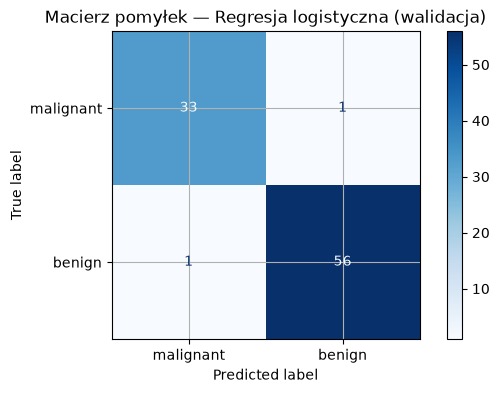

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lr,
    display_labels=data.target_names,
    cmap="Blues",
)
plt.title("Macierz pomyłek — Regresja logistyczna (walidacja)")
plt.show()


## Ćwiczenie 4

- Stwórz prostą sieć MLP w PyTorch.
- Uzupełnij lub zmień architekturę: liczbę warstw, liczbę neuronów i funkcje aktywacji.
- Zwróć uwagę, że `BCEWithLogitsLoss` oczekuje logitów, więc ostatnia warstwa nie ma sigmoidu.

In [10]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(RANDOM_STATE)

def make_loader(X_array, y_array, batch_size=32, shuffle=False):
    X_tensor = torch.tensor(X_array, dtype=torch.float32)
    y_tensor = torch.tensor(y_array.reshape(-1, 1), dtype=torch.float32)
    return DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, batch_size=32, shuffle=True)
val_loader = make_loader(X_val, y_val, batch_size=128, shuffle=False)

n_features = X_train.shape[1]

model = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)

model


Sequential(
  (0): Linear(in_features=30, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)

## Ćwiczenie 5

- Wytrenuj model.
- Narysuj krzywe uczenia dla funkcji straty i dokładności.
- Porównaj wynik na treningu i walidacji.

In [11]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        if is_train:
            optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        if is_train:
            loss.backward()
            optimizer.step()

        preds = (torch.sigmoid(logits) > 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
        total_loss += loss.item() * y_batch.size(0)

    return total_loss / total, correct / total

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

EPOCHS = 100
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None)

    history["loss"].append(train_loss)
    history["accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{EPOCHS} - loss: {train_loss:.4f}, acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}")


Epoch   1/100 - loss: 0.6617, acc: 0.5357, val_loss: 0.6070, val_acc: 0.8681
Epoch  20/100 - loss: 0.0319, acc: 0.9918, val_loss: 0.0675, val_acc: 0.9780
Epoch  40/100 - loss: 0.0103, acc: 0.9973, val_loss: 0.0686, val_acc: 0.9780
Epoch  60/100 - loss: 0.0027, acc: 1.0000, val_loss: 0.0800, val_acc: 0.9780
Epoch  80/100 - loss: 0.0010, acc: 1.0000, val_loss: 0.0901, val_acc: 0.9780
Epoch 100/100 - loss: 0.0005, acc: 1.0000, val_loss: 0.0971, val_acc: 0.9780


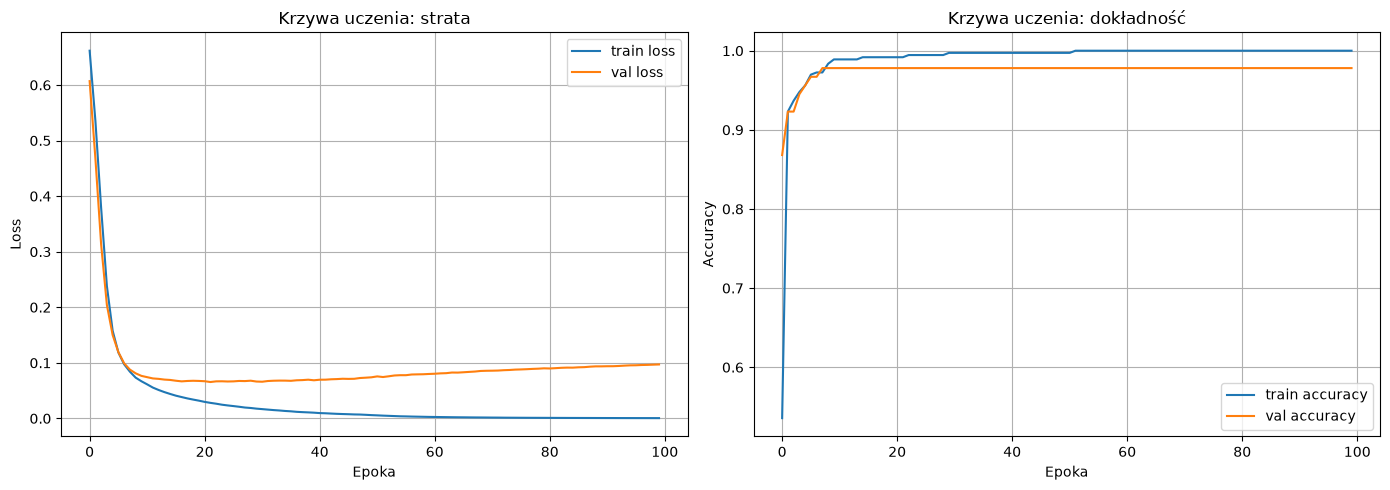

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history["loss"], label="train loss")
ax1.plot(history["val_loss"], label="val loss")
ax1.set_xlabel("Epoka")
ax1.set_ylabel("Loss")
ax1.set_title("Krzywa uczenia: strata")
ax1.legend()

ax2.plot(history["accuracy"], label="train accuracy")
ax2.plot(history["val_accuracy"], label="val accuracy")
ax2.set_xlabel("Epoka")
ax2.set_ylabel("Accuracy")
ax2.set_title("Krzywa uczenia: dokładność")
ax2.legend()

plt.tight_layout()
plt.show()


In [13]:
def predict_torch(model, X_eval):
    model.eval()
    X_tensor = torch.tensor(X_eval, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_tensor)
        probs = torch.sigmoid(logits).numpy().ravel()
    y_pred = (probs >= 0.5).astype("int64")
    return y_pred, probs

y_pred_val, y_score_val = predict_torch(model, X_val)
evaluate_predictions("MLP PyTorch (walidacja)", y_val, y_pred_val, y_score_val)


## MLP PyTorch (walidacja)
  Accuracy:          0.9780
  Balanced accuracy: 0.9765
  ROC AUC:           0.9969
              precision    recall  f1-score   support

   malignant       0.97      0.97      0.97        34
      benign       0.98      0.98      0.98        57

    accuracy                           0.98        91
   macro avg       0.98      0.98      0.98        91
weighted avg       0.98      0.98      0.98        91



## Cwiczenie 6

- Zbuduj kontrolowany przyklad przeuczenia.
- Wez bardzo maly podzbior treningowy i celowo zastap jego etykiety losowymi etykietami.
- Wytrenuj duzy model bez regularyzacji tak, aby mogl zapamietac te przyklady.
- Porownaj accuracy/loss na malym zbiorze treningowym oraz na normalnym zbiorze walidacyjnym.

To nie jest poprawna procedura uczenia. To eksperyment pokazujacy, ze duzy model moze nauczyc sie szumu na train, ale nie uogolni tego na validation.

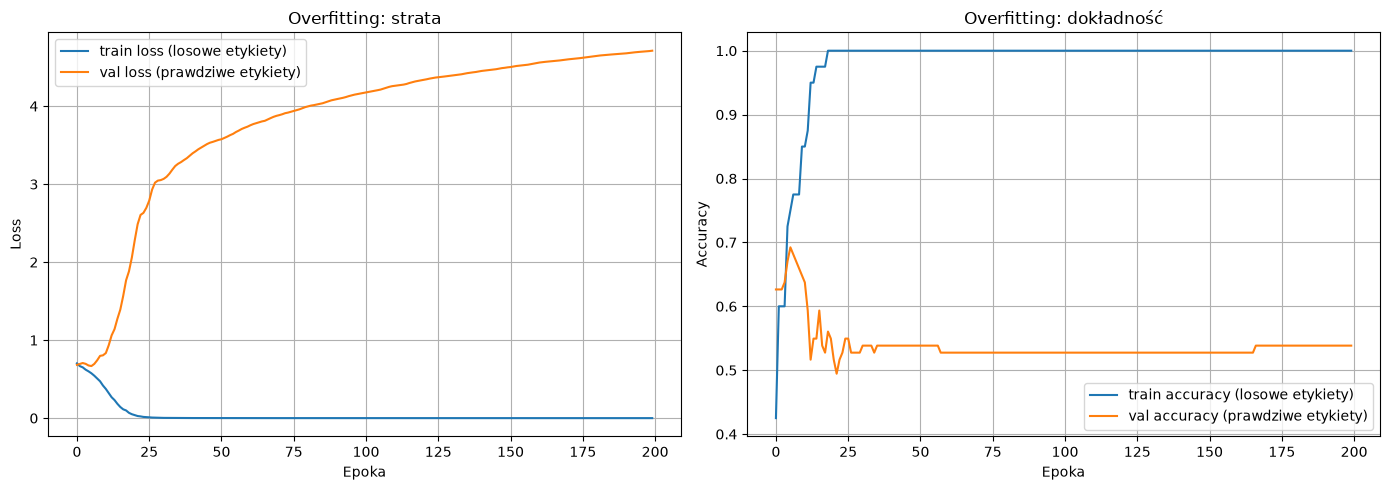

In [14]:
N_SMALL = 40
idx_small = np.random.choice(len(X_train), N_SMALL, replace=False)
X_small = X_train[idx_small]
y_small_random = np.random.randint(0, 2, size=N_SMALL).astype("int64")

small_loader = make_loader(X_small, y_small_random, batch_size=16, shuffle=True)

torch.manual_seed(RANDOM_STATE)
overfit_model = nn.Sequential(
    nn.Linear(n_features, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 1),
)
overfit_optimizer = torch.optim.Adam(overfit_model.parameters(), lr=0.001)

overfit_history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
OVERFIT_EPOCHS = 200
for epoch in range(1, OVERFIT_EPOCHS + 1):
    t_loss, t_acc = run_epoch(overfit_model, small_loader, overfit_optimizer)
    v_loss, v_acc = run_epoch(overfit_model, val_loader, optimizer=None)
    overfit_history["loss"].append(t_loss)
    overfit_history["accuracy"].append(t_acc)
    overfit_history["val_loss"].append(v_loss)
    overfit_history["val_accuracy"].append(v_acc)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(overfit_history["loss"], label="train loss (losowe etykiety)")
ax1.plot(overfit_history["val_loss"], label="val loss (prawdziwe etykiety)")
ax1.set_xlabel("Epoka")
ax1.set_ylabel("Loss")
ax1.set_title("Overfitting: strata")
ax1.legend()

ax2.plot(overfit_history["accuracy"], label="train accuracy (losowe etykiety)")
ax2.plot(overfit_history["val_accuracy"], label="val accuracy (prawdziwe etykiety)")
ax2.set_xlabel("Epoka")
ax2.set_ylabel("Accuracy")
ax2.set_title("Overfitting: dokładność")
ax2.legend()

plt.tight_layout()
plt.show()


## Ćwiczenie 7

- Uruchom sztuczny przykład data leakage.
- Wyjaśnij, dlaczego wynik takiego modelu nie może być traktowany jako prawdziwa ocena jakości.

In [15]:
X_with_leak = np.column_stack([X, y]).astype("float32")

X_leak_train, X_leak_test, y_leak_train, y_leak_test = train_test_split(
    X_with_leak, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

leak_scaler = StandardScaler()
X_leak_train_s = leak_scaler.fit_transform(X_leak_train)
X_leak_test_s = leak_scaler.transform(X_leak_test)

torch.manual_seed(RANDOM_STATE)
leak_model = nn.Sequential(
    nn.Linear(X_leak_train_s.shape[1], 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)
leak_optimizer = torch.optim.Adam(leak_model.parameters(), lr=0.001)
leak_train_loader = make_loader(X_leak_train_s, y_leak_train, batch_size=32, shuffle=True)

for epoch in range(1, 51):
    run_epoch(leak_model, leak_train_loader, leak_optimizer)

y_pred_leak, y_score_leak = predict_torch(leak_model, X_leak_test_s)
evaluate_predictions("Model z DATA LEAKAGE (test)", y_leak_test, y_pred_leak, y_score_leak)

print("Wyjaśnienie: Model ma dostęp do kolumny będącej etykietą docelową.")
print("Osiąga 100% accuracy, co w praktyce jest bezwartościowe, bo przy realnej predykcji etykieta nie jest znana.")


## Model z DATA LEAKAGE (test)
  Accuracy:          1.0000
  Balanced accuracy: 1.0000
  ROC AUC:           1.0000
              precision    recall  f1-score   support

   malignant       1.00      1.00      1.00        42
      benign       1.00      1.00      1.00        72

    accuracy                           1.00       114
   macro avg       1.00      1.00      1.00       114
weighted avg       1.00      1.00      1.00       114

Wyjaśnienie: Model ma dostęp do kolumny będącej etykietą docelową.
Osiąga 100% accuracy, co w praktyce jest bezwartościowe, bo przy realnej predykcji etykieta nie jest znana.


## Ćwiczenie 8

- Wybierz model na podstawie wyników walidacyjnych.
- Dopiero teraz użyj zbioru testowego.
- Zapisz końcowe metryki i macierz pomyłek.

## MLP PyTorch (zbiór testowy)
  Accuracy:          0.9649
  Balanced accuracy: 0.9673
  ROC AUC:           0.9931
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



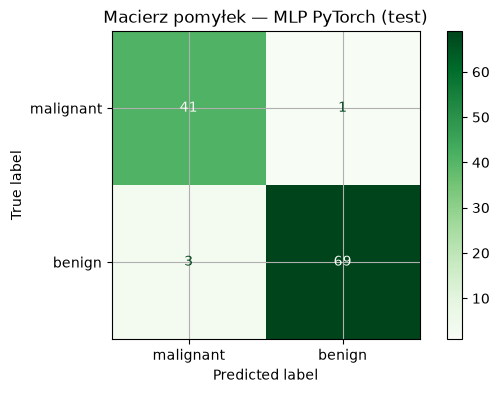

In [16]:
y_pred_test, y_score_test = predict_torch(model, X_test)
evaluate_predictions("MLP PyTorch (zbiór testowy)", y_test, y_pred_test, y_score_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=data.target_names,
    cmap="Greens",
)
plt.title("Macierz pomyłek — MLP PyTorch (test)")
plt.show()
